In [39]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.constants import h, c, e


In [40]:
def gaussian(x, a, x0, sigma):
    return a * np.exp(-(x - x0)**2 / (2 * sigma**2))

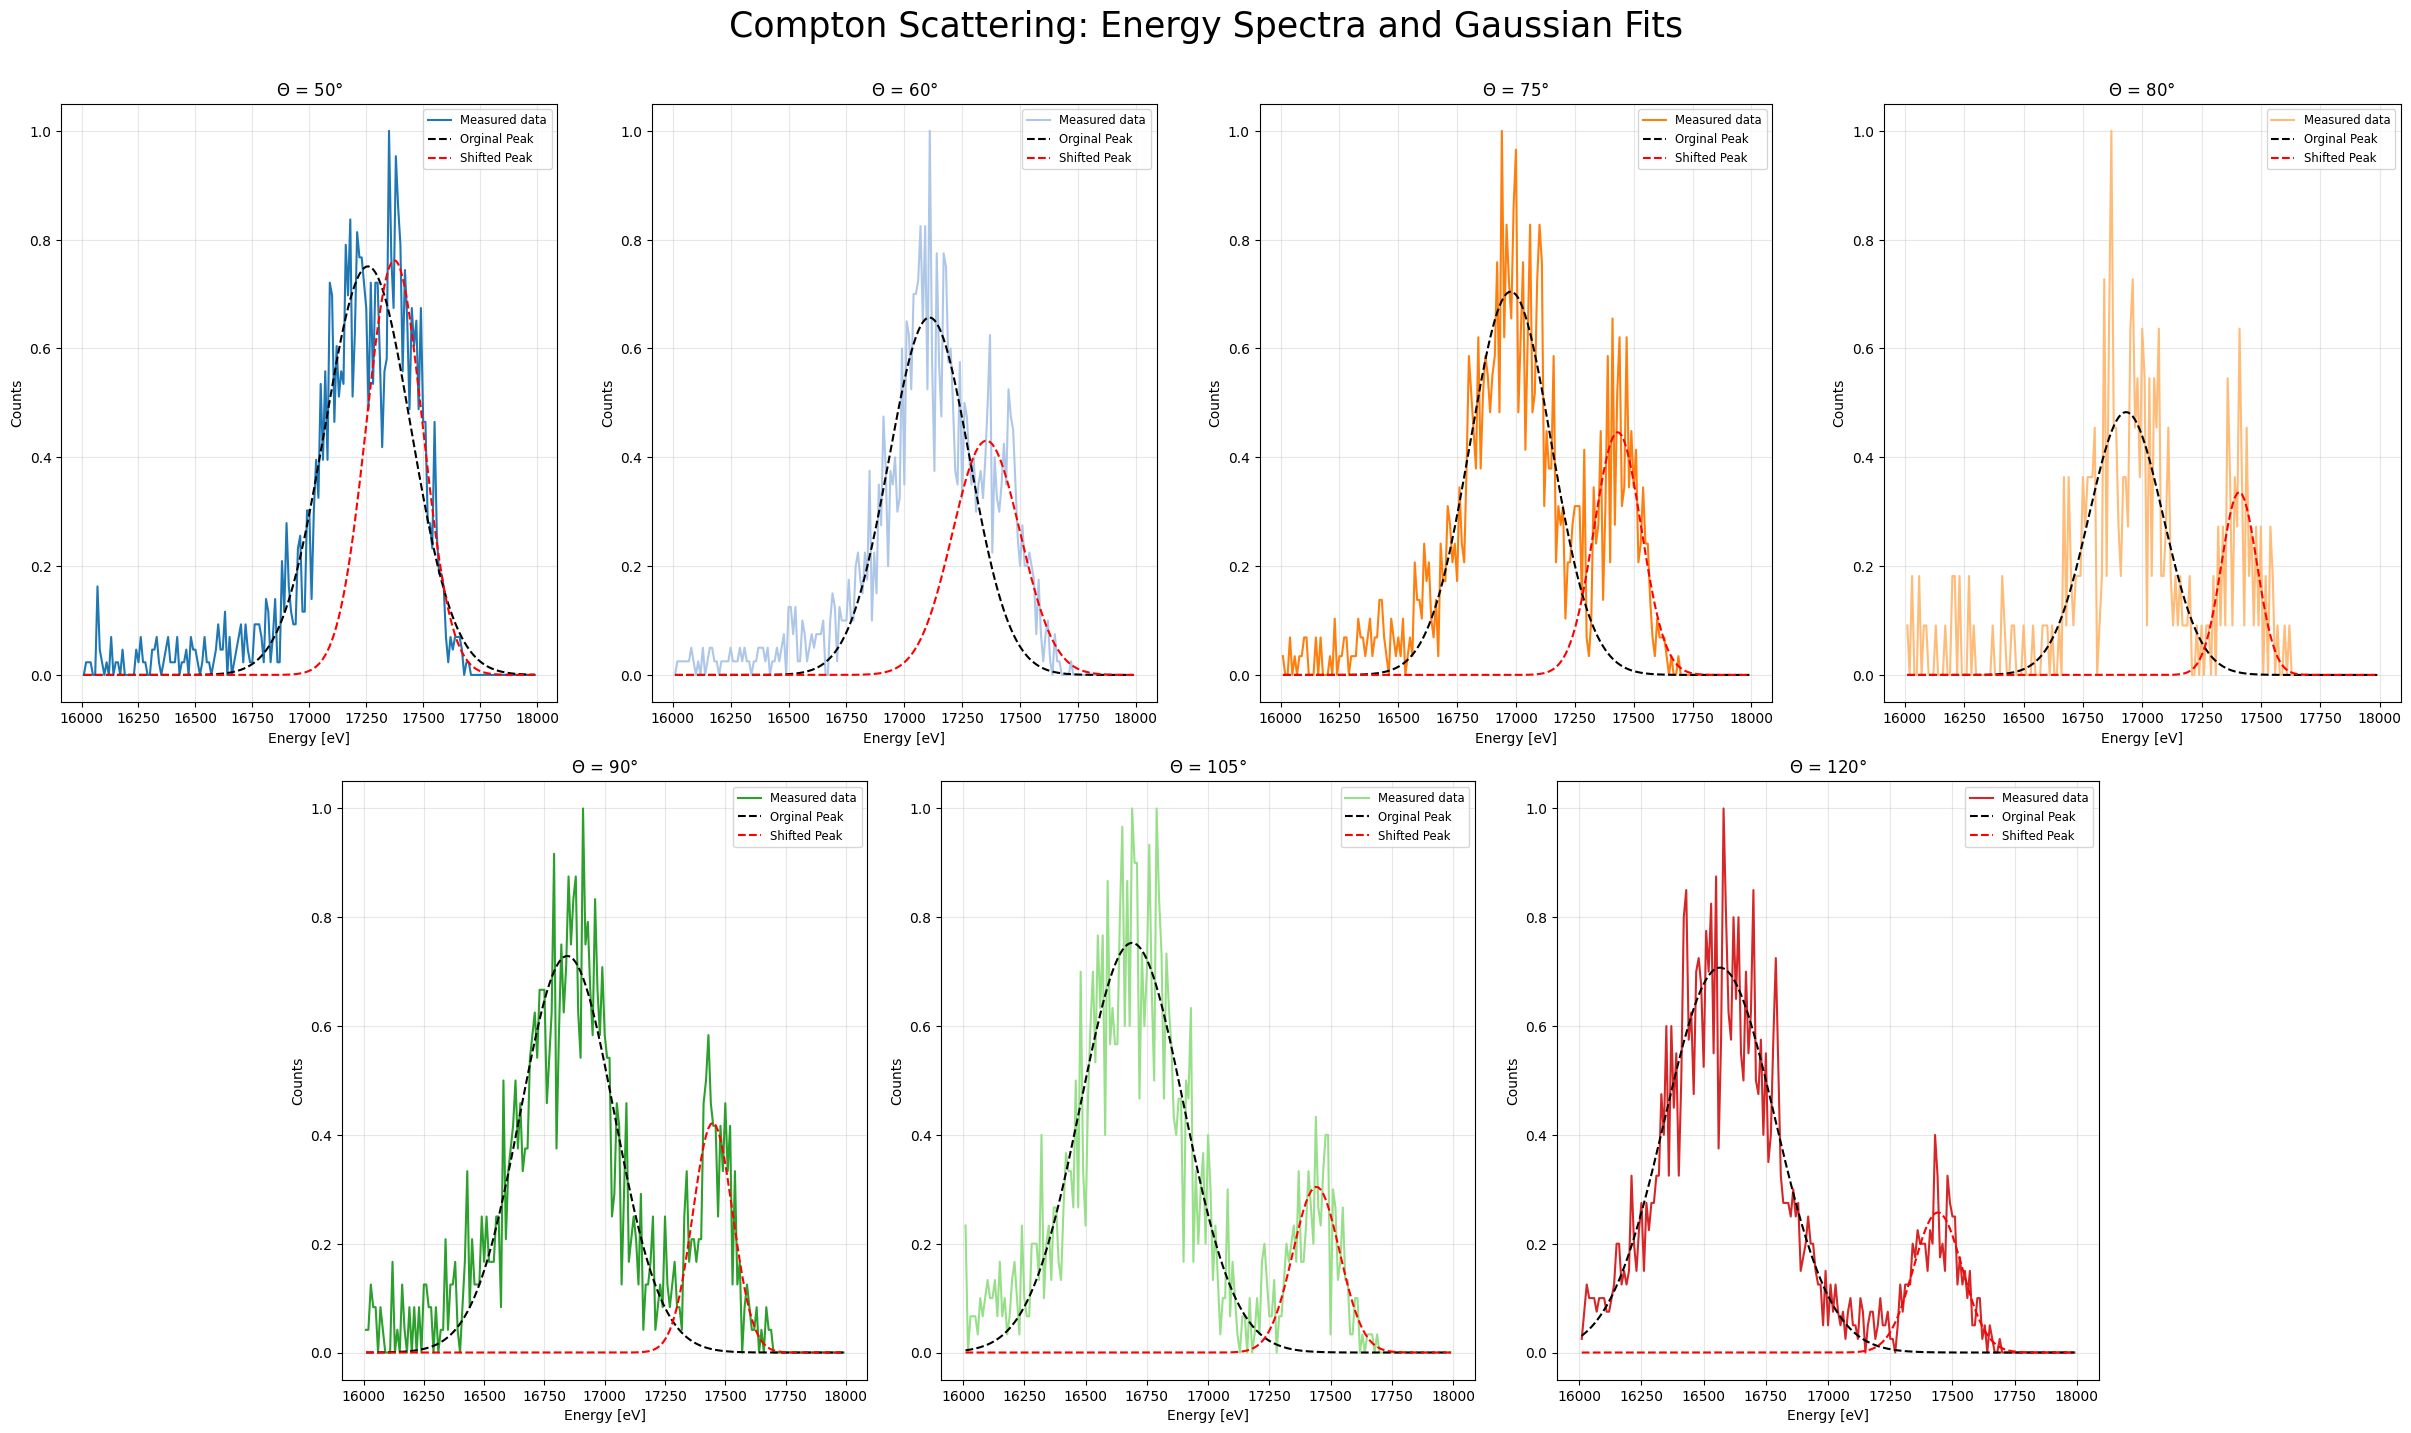

In [41]:
file_path = 'C:\\Users\\kr200\\OneDrive\\Plocha\\SCHOOL\\Applied Physics IV\\RTG+COMPTON\\Compton'
theta = np.array([50,60,75,80,90,105,120])

dfs = {}
E = np.zeros(len(theta))

deltalambda = np.zeros(len(theta))
deltaE = np.zeros(len(theta))

for i in range(len(theta)):
    file_name = f'{theta[i]}deg.mca'
    full_path = f'{file_path}\\{file_name}'
    dfs[theta[i]] = pd.read_csv(full_path, skiprows = 32, names=['Counts'])
    dfs[theta[i]]['E/eV'] =  np.linspace(0, 40950, len(dfs[theta[i]]))
    dfs[theta[i]]['Relative_counts'] = dfs[theta[i]]['Counts'] / dfs[theta[i]]['Counts'].max()



mask = (16000 < dfs[50]['E/eV']) & (dfs[50]['E/eV'] < 18000)

cmap_tab10 = mpl.colormaps['tab20']


layout = [
    ['A', 'A', 'B', 'B', 'C', 'C', 'D', 'D'],
    ['.', 'E', 'E', 'F', 'F', 'G', 'G', '.']
]

fig, axs_dict = plt.subplot_mosaic(layout, figsize=(16*1.5, 9*1.5), constrained_layout=True)
#fig, ax = plt.subplots(figsize=(16, 9))
# Převedeme slovník subplotů na seznam pro snadné indexování cyklem
axs = list(axs_dict.values())

for i in range(len(theta)):
    ax = axs[i]  # Aktuální subplot pro daný úhel
    
    # 1. Definice masek pro jednotlivá okna fitování
    if i == 0:
        mask1 = (16750 < dfs[theta[i]]['E/eV']) & (dfs[theta[i]]['E/eV'] < 17200)
    else:
        mask1 = (16000 < dfs[theta[i]]['E/eV']) & (dfs[theta[i]]['E/eV'] < 17250)
    
    # OPRAVA: mask2 by měla vycházet z aktuálního dfs[theta[i]], ne natvrdo dfs[60]
    mask2 = (17250 < dfs[theta[i]]['E/eV']) & (dfs[theta[i]]['E/eV'] < 18000)

    # 2. Fitování Gaussů
    popt1, pcov1 = curve_fit(gaussian, dfs[theta[i]]['E/eV'][mask1], dfs[theta[i]]['Relative_counts'][mask1], p0=[100, 16900, 10])
    popt2, pcov2 = curve_fit(gaussian, dfs[theta[i]]['E/eV'][mask2], dfs[theta[i]]['Relative_counts'][mask2], p0=[40, 17200, 50])

    a1, x01, sigma1 = popt1
    a2, x02, sigma2 = popt2

    deltalambda[i] = h * c / (x01 * e) - h * c / (x02 * e)
    deltaE[i] = x02 - x01
    E[i] = x01

    # Celková maska pro rozsah zobrazovaných dat v grafu
    plot_mask = (dfs[theta[i]]['E/eV'] > 16000) & (dfs[theta[i]]['E/eV'] < 18000)
    
    # 3. Vykreslení do konkrétního subplotu
    ax.plot(dfs[theta[i]]['E/eV'][plot_mask], dfs[theta[i]]['Relative_counts'][plot_mask], label=f'Measured data', color=cmap_tab10(i))
    ax.plot(dfs[theta[i]]['E/eV'][plot_mask], gaussian(dfs[theta[i]]['E/eV'][plot_mask], *popt1), 'k--', label='Orginal Peak')
    ax.plot(dfs[theta[i]]['E/eV'][plot_mask], gaussian(dfs[theta[i]]['E/eV'][plot_mask], *popt2), 'r--', label='Shifted Peak')
    
    # Nastavení popisků a mřížky
    ax.set_title(f'$\\Theta$ = {theta[i]}°')
    ax.set_xlabel('Energy [eV]')
    ax.set_ylabel('Counts')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize='small')

fig.suptitle('Compton Scattering: Energy Spectra and Gaussian Fits', fontsize=25, y=1.05)
#plt.tight_layout()
plt.show()
fig.savefig('C:\\Users\\kr200\\OneDrive\\Plocha\\SCHOOL\\Applied Physics IV\\RTG+COMPTON\\Compton\\Compton_Scattering_Fits.png', dpi=300, bbox_inches='tight')

GIF úspěšně uložen do: C:\Users\kr200\OneDrive\Plocha\SCHOOL\Applied Physics IV\RTG+COMPTON\Compton\Compton_Animation.gif
Video úspěšně uloženo do: C:\Users\kr200\OneDrive\Plocha\SCHOOL\Applied Physics IV\RTG+COMPTON\Compton\Compton_Animation.mp4


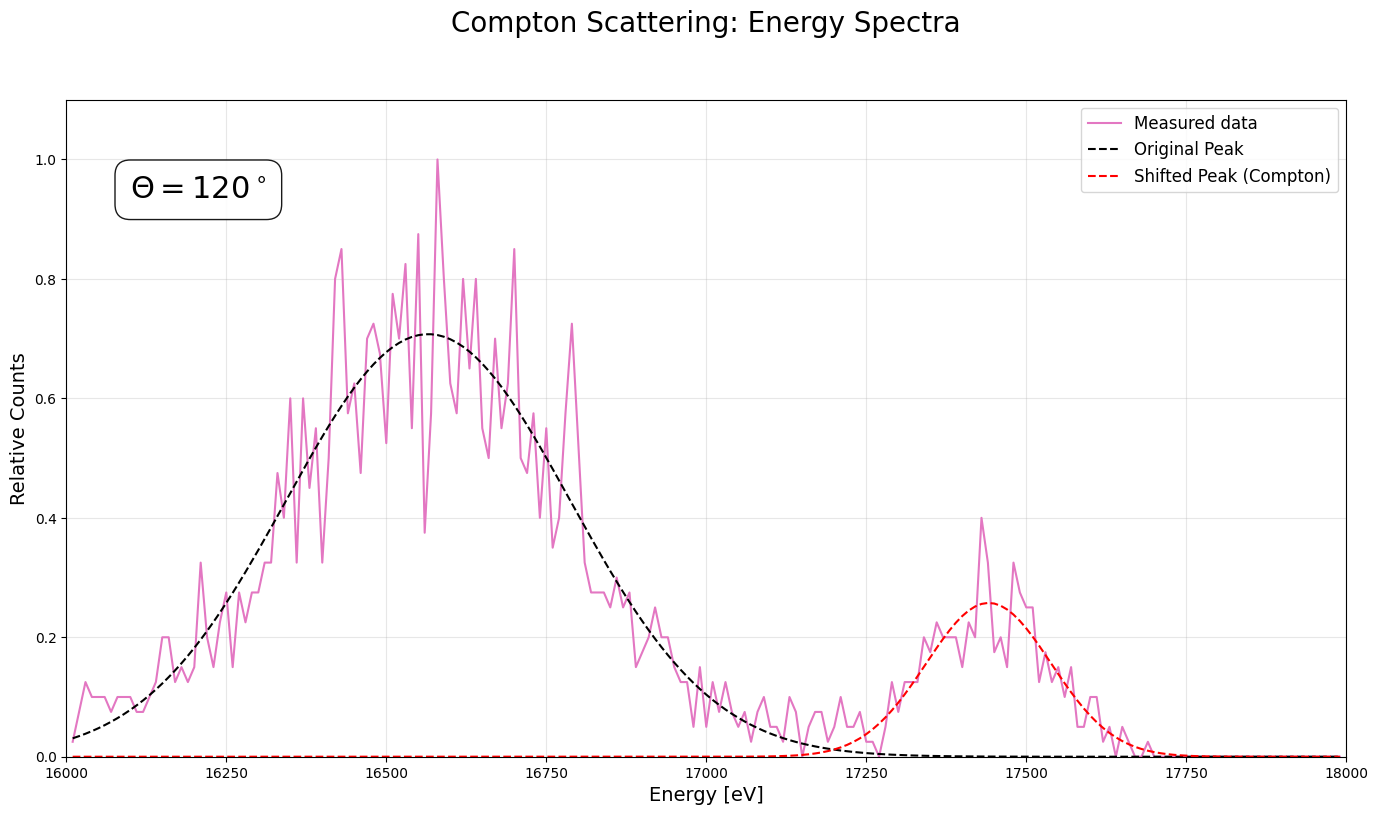

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import curve_fit
from matplotlib.animation import FuncAnimation
import os

# Definice Gaussovy funkce
def gaussian(x, a, x0, sigma):
    return a * np.exp(-(x - x0)**2 / (2 * sigma**2))

# Cesta k souborům (použijte svou skutečnou cestu, pokud se liší)
file_path = r'C:\Users\kr200\OneDrive\Plocha\SCHOOL\Applied Physics IV\RTG+COMPTON\Compton'
save_dir = r'C:\Users\kr200\OneDrive\Plocha\SCHOOL\Applied Physics IV\RTG+COMPTON\Compton'

# Úhly a pole pro data
theta = np.array([50, 60, 75, 80, 90, 105, 120])
dfs = {}
popt1_dict = {}
popt2_dict = {}

# 1. NAČTENÍ DAT A VÝPOČET FITŮ PŘED ANIMACÍ
# Zkontrolujte, zda cesta existuje
if not os.path.exists(file_path):
    print(f"Chyba: Cesta '{file_path}' neexistuje.")
    exit()

for i in range(len(theta)):
    file_name = f'{theta[i]}deg.mca'
    full_path = os.path.join(file_path, file_name)
    
    # Načtení dat (pokud soubor existuje)
    if not os.path.exists(full_path):
        print(f"Varování: Soubor '{full_path}' nebyl nalezen.")
        continue

    df = pd.read_csv(full_path, skiprows=32, names=['Counts'])
    df['E/eV'] = np.linspace(0, 40950, len(df))
    df['Relative_counts'] = df['Counts'] / df['Counts'].max()
    dfs[theta[i]] = df
    
    # Masky pro fitování
    if i == 0:
        mask1 = (16750 < df['E/eV']) & (df['E/eV'] < 17200)
    else:
        mask1 = (16000 < df['E/eV']) & (df['E/eV'] < 17250)
        
    mask2 = (17250 < df['E/eV']) & (df['E/eV'] < 18000)

    # Fitování Gaussů (s ošetřením možných chyb)
    try:
        popt1, _ = curve_fit(gaussian, df['E/eV'][mask1], df['Relative_counts'][mask1], p0=[100, 16900, 10])
        popt2, _ = curve_fit(gaussian, df['E/eV'][mask2], df['Relative_counts'][mask2], p0=[40, 17200, 50])
        
        popt1_dict[theta[i]] = popt1
        popt2_dict[theta[i]] = popt2
    except RuntimeError:
        print(f"Varování: Fitování selhalo pro úhel {theta[i]}.")
        popt1_dict[theta[i]] = None
        popt2_dict[theta[i]] = None

# Zkontrolovat, zda máme nějaká data
if not dfs:
    print("Chyba: Žádná data nebyla načtena.")
    exit()

# 2. PŘÍPRAVA OBRÁZKU PRO ANIMACI
# Nastavit rozměry a zakázat automatické rozvržení
fig, ax = plt.subplots(figsize=(16, 9), constrained_layout=False)
cmap_tab10 = mpl.colormaps['tab10']

# === NOVÉ: Nastavení pevných okrajů pro celý obrázek ===
# Vyzkoušejte tyto hodnoty, aby se popisky a nadpisy vešly
fig.subplots_adjust(left=0.10, bottom=0.15, right=0.90, top=0.88)

# Přidat hlavní nadpis pro celý obrázek, který je stabilní
fig.suptitle('Compton Scattering: Energy Spectra', fontsize=20)

# Inicializační funkce pro animaci
def init():
    # Nastavení os, která se nemění
    ax.set_xlabel('Energy [eV]', fontsize=14)
    ax.set_ylabel('Relative Counts', fontsize=14)
    ax.set_xlim(16000, 18000)
    ax.set_ylim(0, 1.1)
    ax.grid(True, alpha=0.3)
    return ax,

# 3. ANIMAČNÍ FUNKCE
def animate(i):
    # Vyčistit jen osy, ne celý obrázek
    ax.clear()
    
    # Znovu nastavit popisky po vyčištění (nebo je nastavit v init a nečistit je)
    # Lepší je nastavit popisky uvnitř animate, pokud čistíme celou osu
    ax.set_xlabel('Energy [eV]', fontsize=14)
    ax.set_ylabel('Relative Counts', fontsize=14)
    ax.set_xlim(16000, 18000)
    ax.set_ylim(0, 1.1)
    ax.grid(True, alpha=0.3)
    
    current_theta = theta[i]
    if current_theta not in dfs or popt1_dict[current_theta] is None:
        return ax,
        
    df = dfs[current_theta]
    popt1 = popt1_dict[current_theta]
    popt2 = popt2_dict[current_theta]
    
    plot_mask = (df['E/eV'] > 16000) & (df['E/eV'] < 18000)
    x_data = df['E/eV'][plot_mask]
    y_data = df['Relative_counts'][plot_mask]
    
    # Vykreslení dat
    ax.plot(x_data, y_data, label='Measured data', color=cmap_tab10(i % 10), lw=1.5)
    
    # Vykreslení fitů
    # Původní pík (K-alfa) - černá přerušovaná, menší šířka čáry
    ax.plot(x_data, gaussian(x_data, *popt1), 'k--', label='Original Peak', lw=1.5)
    
    # Comptonův pík - červená přerušovaná
    ax.plot(x_data, gaussian(x_data, *popt2), 'r--', label='Shifted Peak (Compton)', lw=1.5)
    
    # Přidání textu s úhlem Theta
    ax.text(0.05, 0.85, f'$\\Theta = {current_theta}^\\circ$', 
            transform=ax.transAxes, 
            fontsize=22, 
            fontweight='bold', 
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='black', boxstyle='round,pad=0.5'))
    
    # Legenda - vpravo nahoře
    ax.legend(fontsize=12, loc='upper right')
    
    return ax,

# 4. SPUŠTĚNÍ A ULOŽENÍ ANIMACE
# interval=1000ms = 1 frame za sekundu, repeat_delay prodleva na konci
ani = FuncAnimation(fig, animate, init_func=init, frames=len(theta), interval=1000, repeat=True, repeat_delay=2000, blit=False)

# Odstranit plt.tight_layout(), protože jsme nastavili pevné okraje

import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter

# 1. POKUD SIS FFMPEG STÁHL RUČNĚ, ODKOMENTUJ TENTO ŘÁDEK A ZADEJ SPRÁVNOU CESTU K ffmpeg.exe:
plt.rcParams['animation.ffmpeg_path'] = r'C:\ffmpeg\bin\ffmpeg.exe'

save_path_gif = r'C:\Users\kr200\OneDrive\Plocha\SCHOOL\Applied Physics IV\RTG+COMPTON\Compton\Compton_Animation.gif'
save_path_mp4 = r'C:\Users\kr200\OneDrive\Plocha\SCHOOL\Applied Physics IV\RTG+COMPTON\Compton\Compton_Animation.mp4'

# Uložení jako GIF (potřebuje knihovnu Pillow)
ani.save(save_path_gif, dpi=300, writer='pillow')
print(f"GIF úspěšně uložen do: {save_path_gif}")

# Uložení jako MP4
try:
    writer = FFMpegWriter(fps=1, metadata=dict(artist='Me'), bitrate=1800)
    ani.save(save_path_mp4, writer=writer, dpi=150)
    print(f"Video úspěšně uloženo do: {save_path_mp4}")
except FileNotFoundError:
    print("\nCHYBA: FFmpeg nebyl nalezen!")
    print("Nainstaluj ho přes 'conda install -c conda-forge ffmpeg' nebo ho stáhni ručně.")

plt.show()

In [45]:
def compton_wavelength_shift(theta, wavelength):
    return wavelength * (1 - np.cos(np.radians(theta)))

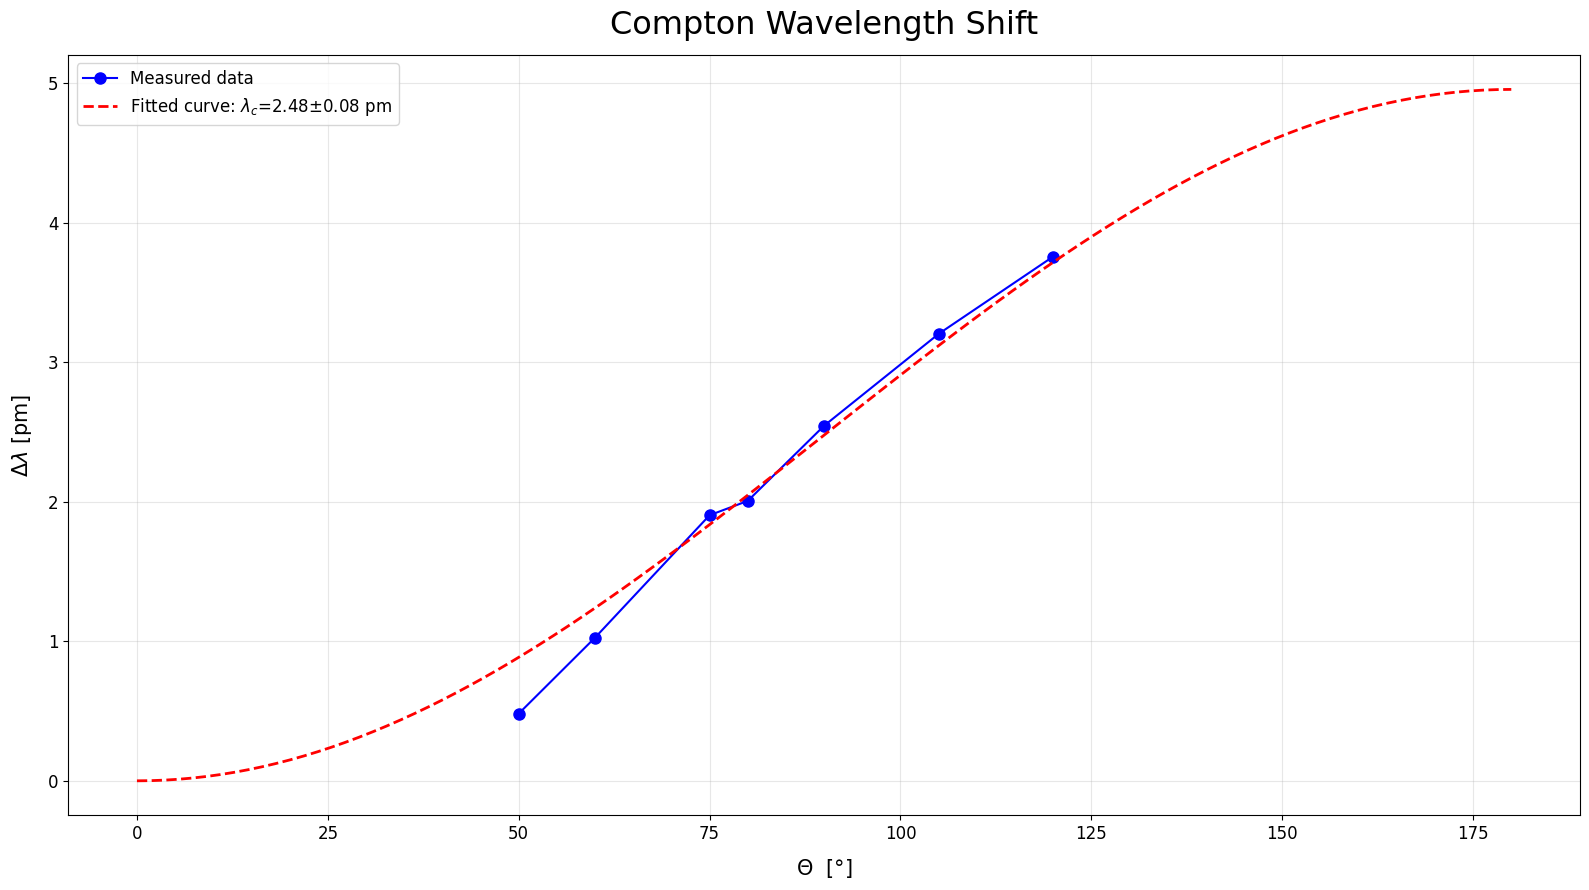

Compton wavelength: 2.48+/-0.08 pm


In [46]:
popt, pcovt = curve_fit(compton_wavelength_shift, theta, deltalambda)

compton_wavelength = popt[0]
compton_wavelength_uncertainty = np.sqrt(np.diag(pcovt))[0]

from uncertainties import ufloat as uf

ucompton_wavelength = uf(compton_wavelength, compton_wavelength_uncertainty)

theta_fit = np.linspace(0, 180, 100)

fig, ax = plt.subplots(figsize=(16, 9))
ax.plot(theta, deltalambda * 1e12, 'o-', label='Measured data', markersize=8, color='b')
ax.plot(theta_fit, compton_wavelength_shift(theta_fit, *popt) * 1e12, 'r--', label='Fitted curve: $\\lambda_c$=' + f'{ucompton_wavelength * 1e12:.1uP} pm', linewidth=2)

ax.set_xlabel('$\\Theta$  [°]', fontsize=15, labelpad=10)
ax.set_ylabel('$\\Delta\\lambda$ [pm]', fontsize=15, labelpad=10)
ax.grid(True, alpha=0.3)
ax.set_title('Compton Wavelength Shift', fontsize=23, pad=15)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()
fig.savefig('C:\\Users\\kr200\\OneDrive\\Plocha\\SCHOOL\\Applied Physics IV\\RTG+COMPTON\\Compton\\compton_wavelength_shift.png', dpi=300)
print(f'Compton wavelength: {ucompton_wavelength * 1e12} pm')
#ax.plot(theta, deltaE, 'o-')

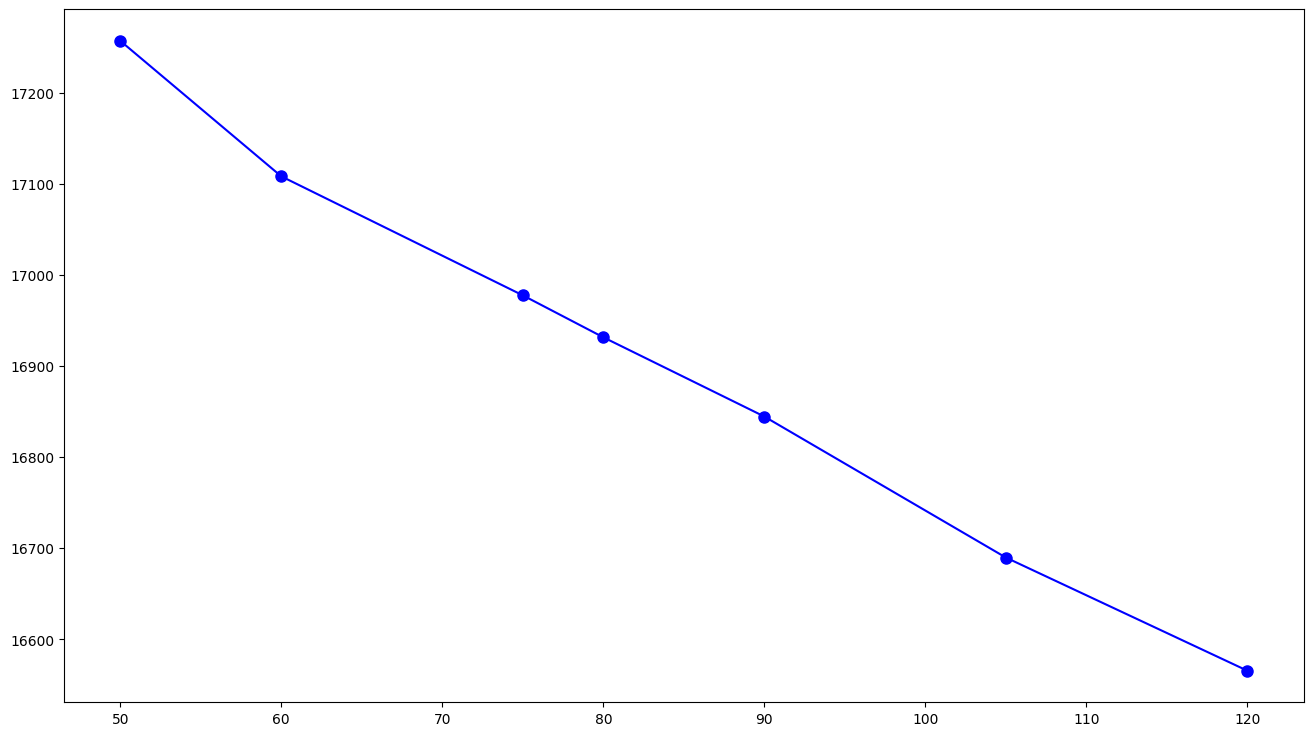

In [47]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.plot(theta,E, 'o-', label='Measured data', markersize=8, color='b')